# Aulas IA Preditiva Modulo1 Semana 09 Aula3

### Programacao orientada a objetos para manipulação de dados

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from script_functions import barras_vertical, barras_horizontal, pizza, linhas, dispersao, mostrar

dados = pd.read_csv("vendas.csv", parse_dates=["data"])
print(dados.shape)


(180, 13)


In [62]:
print(list(dados.columns))

print(dados["categoria"].unique())

dados.head(5)

['id_venda', 'data', 'categoria', 'regiao', 'canal', 'quantidade', 'preco_unitario', 'faturamento', 'quantidade_ruido', 'id_ruido', 'preco_ruido', 'regiao_ruido', 'faturamento_ruido']
['Papelaria' 'Eletrônicos' 'Casa']


,id_venda,data,categoria,regiao,canal,quantidade,preco_unitario,faturamento,quantidade_ruido,id_ruido,preco_ruido,regiao_ruido,faturamento_ruido
0,1,2025-01-01,Papelaria,Sul,Loja,3,22,66,NaN,1,2200,Sul,-66
1,2,2025-02-02,Eletrônicos,Sul,Loja,5,172,860,5.0,1,172,SUL,860
2,3,2025-03-03,Papelaria,Sudeste,Loja,1,17,17,1.0,1,17,Sudeste,17
3,4,2025-04-04,Eletrônicos,Sul,Loja,5,176,880,5.0,4,176,SUL,880
4,5,2025-05-05,Papelaria,Nordeste,Online,2,29,58,2.0,5,29,Nordeste,58


In [10]:
dados.describe()

,id_venda,data,quantidade,preco_unitario,faturamento,quantidade_ruido,id_ruido,preco_ruido,faturamento_ruido
count,180.000000,180,180.000000,180.000000,180.000000,160.000000,180.000000,180.000000,180.000000
mean,90.500000,2025-03-30 03:12:00,3.005556,94.188889,289.988889,3.037500,90.483333,106.288889,242.766667
min,1.000000,2025-01-01 00:00:00,1.000000,15.000000,17.000000,1.000000,1.000000,15.000000,-875.000000
25%,45.750000,2025-02-14 00:00:00,2.000000,31.000000,82.000000,2.000000,45.750000,31.000000,75.000000
50%,90.500000,2025-03-30 00:00:00,3.000000,76.000000,187.000000,3.000000,90.500000,76.500000,171.500000
75%,135.250000,2025-05-13 00:00:00,4.000000,172.000000,371.500000,5.000000,135.250000,172.750000,364.250000
max,180.000000,2025-06-28 00:00:00,5.000000,190.000000,940.000000,5.000000,180.000000,2200.000000,940.000000
std,52.105662,NaN,1.451246,64.291218,264.121522,1.474682,52.134171,169.500531,308.315791


In [14]:
dados.dtypes

id_venda                      int64
data                 datetime64[ns]
categoria                    object
regiao                       object
canal                        object
quantidade                    int64
preco_unitario                int64
faturamento                   int64
quantidade_ruido            float64
id_ruido                      int64
preco_ruido                   int64
regiao_ruido                 object
faturamento_ruido             int64
dtype: object

In [ ]:
limpos = dados.iloc[:, :8].copy()

In [17]:
print(limpos.dtypes)

limpos.head(5)

id_venda                   int64
data              datetime64[ns]
categoria                 object
regiao                    object
canal                     object
quantidade                 int64
preco_unitario             int64
faturamento                int64
dtype: object


,id_venda,data,categoria,regiao,canal,quantidade,preco_unitario,faturamento
0,1,2025-01-01,Papelaria,Sul,Loja,3,22,66
1,2,2025-02-02,Eletrônicos,Sul,Loja,5,172,860
2,3,2025-03-03,Papelaria,Sudeste,Loja,1,17,17
3,4,2025-04-04,Eletrônicos,Sul,Loja,5,176,880
4,5,2025-05-05,Papelaria,Nordeste,Online,2,29,58


In [63]:
class AnaliseVendas:
    # Inicializa os atributos do objeto.
    def __init__(self, tabela):
        self.brutos = tabela.copy()
        self.dados = tabela.iloc[:, :8].copy()

    # Calcula o total das vendas ou da coluna escolhida.
    def total(self, coluna="faturamento", tabela=None):
        if tabela is None:
            base = self.dados
        else:
            base = tabela
        return base[coluna].sum()

    # Calcula a média da coluna escolhida.
    def media(self, coluna="faturamento", tabela=None):
        if tabela is None:
            base = self.dados
        else:
            base = tabela
        return round(base[coluna].mean(), 3)

    # Retorna o faturamento total das vendas.
    def faturamento_total(self):
        return self.total()

    # Retorna a mediana do faturamento.
    def mediana(self):
        return self.dados["faturamento"].median()
    
    # Seleciona as vendas acima da média.
    def acima_da_media(self):
        return self.dados[self.dados["faturamento"] > self.media()]
    
    # Executa a função de gráfico com a tabela escolhida.
    def grafico(self, funcao, tabela, x, y, titulo):
        funcao(tabela, x, y, titulo=titulo)

    # Soma os valores por grupo.
    def agrupar(self, coluna, valor="faturamento", tabela=None):
        if tabela is None:
            base = self.dados
        else:
            base = tabela
        return base.groupby(coluna)[valor].sum() \
            .reset_index().sort_values(by=valor, ascending=False)

    # Calcula o ticket médio de cada grupo.
    def medias_por(self, coluna):
        return self.dados.groupby(coluna, as_index=False)["faturamento"].mean() \
            .reset_index().sort_values(by="faturamento", ascending=False)

    # Conta vendas para cada combinação de grupos.
    def cruzar(self, primeira, segunda):
        return pd.crosstab(self.dados[primeira], self.dados[segunda])

    # Cria a coluna de mês a partir da data.
    def preparar_mes(self):
        self.dados["mes"] = self.dados["data"].dt.to_period("M").astype(str)




In [64]:
analise = AnaliseVendas(dados)

print("Resultado:", analise.faturamento_total())

print("preco_unitario: R$ ", analise.total(coluna='preco_unitario'))

unidades = analise.total("quantidade")
print("Unidades:", unidades)

ticket_medio = analise.media()
print("Ticket médio: R$ ", ticket_medio)

analise.dados.head(5)

Resultado: 52198
preco_unitario: R$  16954
Unidades: 541
Ticket médio: R$  289.989


,id_venda,data,categoria,regiao,canal,quantidade,preco_unitario,faturamento
0,1,2025-01-01,Papelaria,Sul,Loja,3,22,66
1,2,2025-02-02,Eletrônicos,Sul,Loja,5,172,860
2,3,2025-03-03,Papelaria,Sudeste,Loja,1,17,17
3,4,2025-04-04,Eletrônicos,Sul,Loja,5,176,880
4,5,2025-05-05,Papelaria,Nordeste,Online,2,29,58


  categoria  faturamento
Eletrônicos        33882
       Casa        14171
  Papelaria         4145


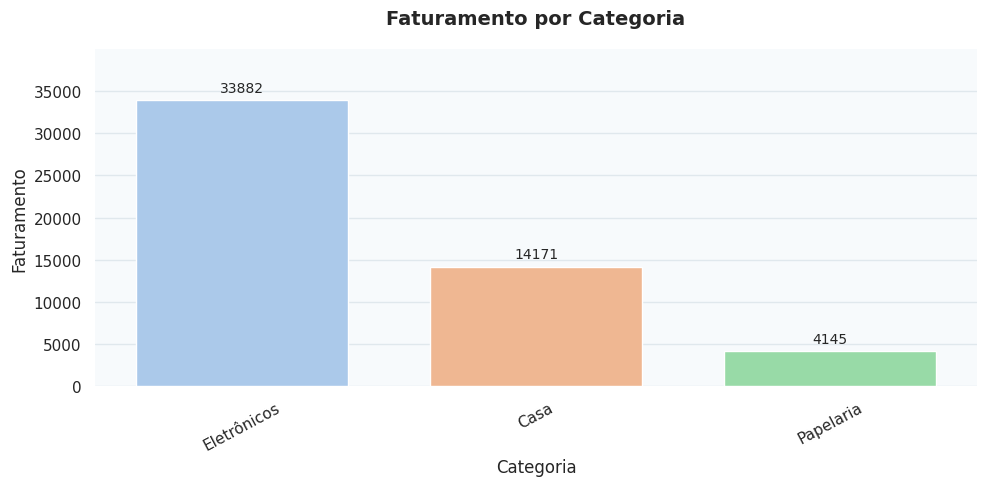

['Papelaria', 'Eletrônicos', 'Casa']


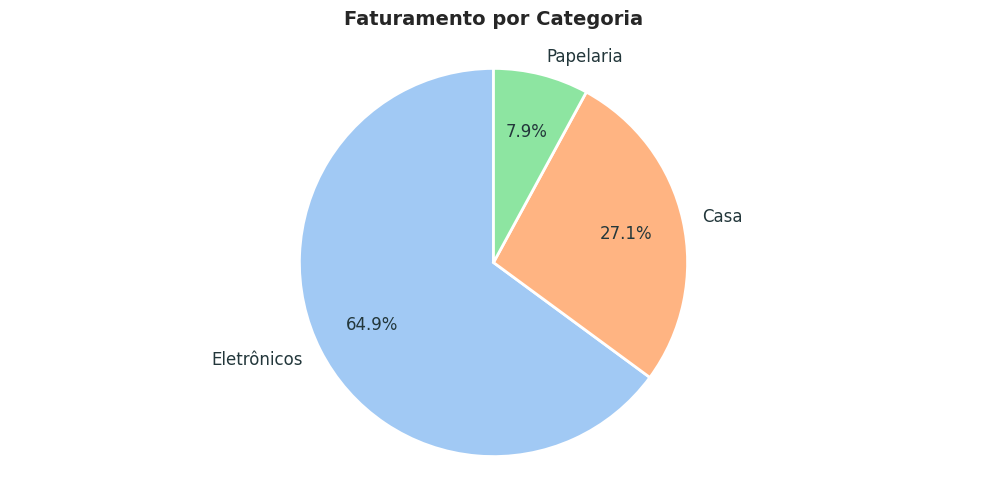

In [75]:
agrupar_por_categoria = analise.agrupar("categoria")
mostrar(agrupar_por_categoria)

analise.grafico(funcao = barras_vertical, tabela = agrupar_por_categoria, \
                x = "categoria", y = "faturamento", titulo = "Faturamento por Categoria")

lista_categoria = list(analise.dados["categoria"].unique())
print(lista_categoria)
analise.grafico(funcao = pizza, tabela = agrupar_por_categoria, \
                x = "categoria", y = "faturamento", titulo = "Faturamento por Categoria")


  regiao  faturamento
     Sul        22160
Nordeste        17347
 Sudeste        12691


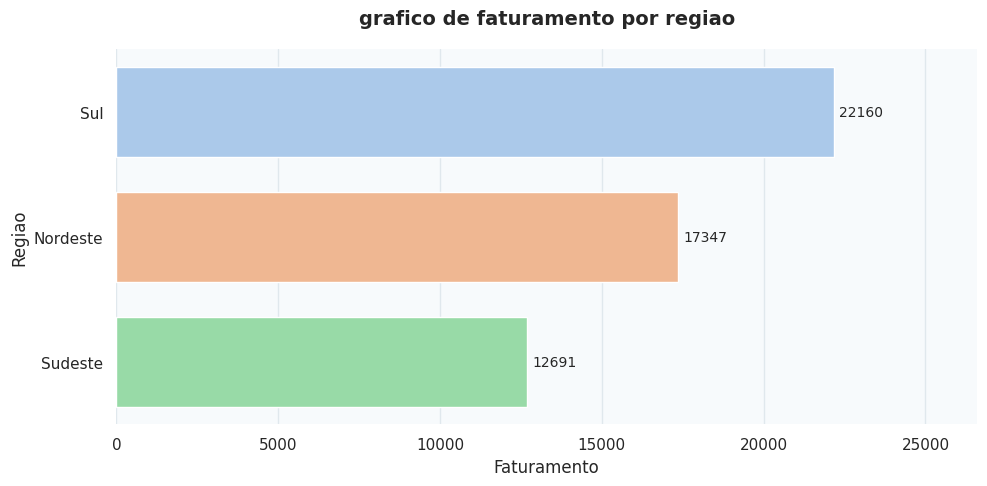

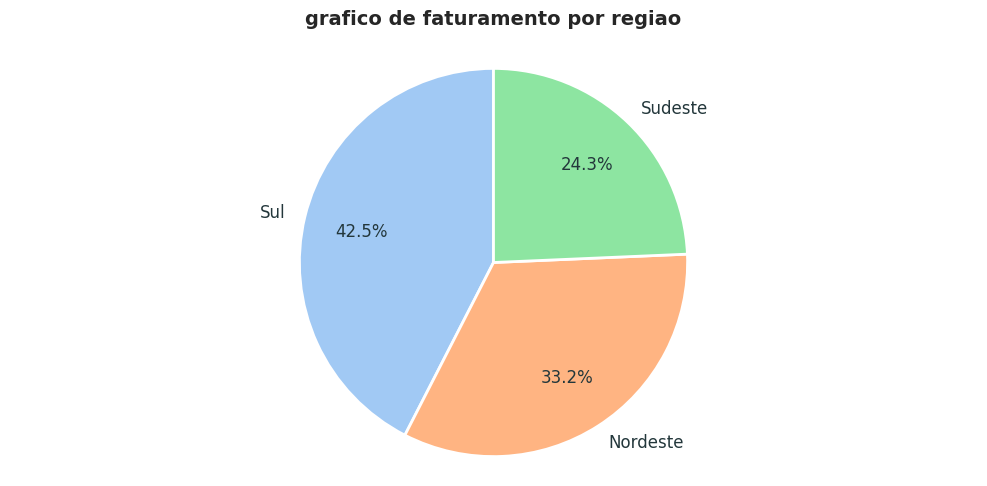

In [79]:
agrupar_por_regiao = analise.agrupar("regiao")
mostrar(agrupar_por_regiao)

analise.grafico(barras_horizontal, agrupar_por_regiao, "regiao", "faturamento", "grafico de faturamento por regiao")

analise.grafico(pizza, agrupar_por_regiao, "regiao", "faturamento", "grafico de faturamento por regiao")

In [81]:
agrupar_por_regiao_categoria = analise.agrupar(["regiao", "categoria", "canal"])
mostrar(agrupar_por_regiao_categoria)

  regiao   categoria  canal  faturamento
     Sul Eletrônicos   Loja         8764
     Sul Eletrônicos Online         7521
Nordeste Eletrônicos   Loja         5418
Nordeste Eletrônicos Online         5260
 Sudeste Eletrônicos Online         3743
 Sudeste        Casa Online         3195
 Sudeste Eletrônicos   Loja         3176
     Sul        Casa   Loja         2889


In [61]:
medias_categoria = analise.medias_por("categoria")
print(type(medias_categoria))
print(analise)

mostrar(medias_categoria)

<class 'pandas.core.frame.DataFrame'>
 index   categoria  faturamento
     1 Eletrônicos       564.70
     0        Casa       228.56
     2   Papelaria        71.47


In [83]:
mostrar(analise.dados)
analise.preparar_mes()
mostrar(analise.dados)

 id_venda       data   categoria   regiao  canal  quantidade  preco_unitario  faturamento
        1 2025-01-01   Papelaria      Sul   Loja           3              22           66
        2 2025-02-02 Eletrônicos      Sul   Loja           5             172          860
        3 2025-03-03   Papelaria  Sudeste   Loja           1              17           17
        4 2025-04-04 Eletrônicos      Sul   Loja           5             176          880
        5 2025-05-05   Papelaria Nordeste Online           2              29           58
        6 2025-06-06   Papelaria  Sudeste   Loja           2              28           56
        7 2025-01-07        Casa  Sudeste   Loja           2              75          150
        8 2025-02-08 Eletrônicos      Sul Online           1             181          181
 id_venda       data   categoria   regiao  canal  quantidade  preco_unitario  faturamento     mes
        1 2025-01-01   Papelaria      Sul   Loja           3              22           66 20

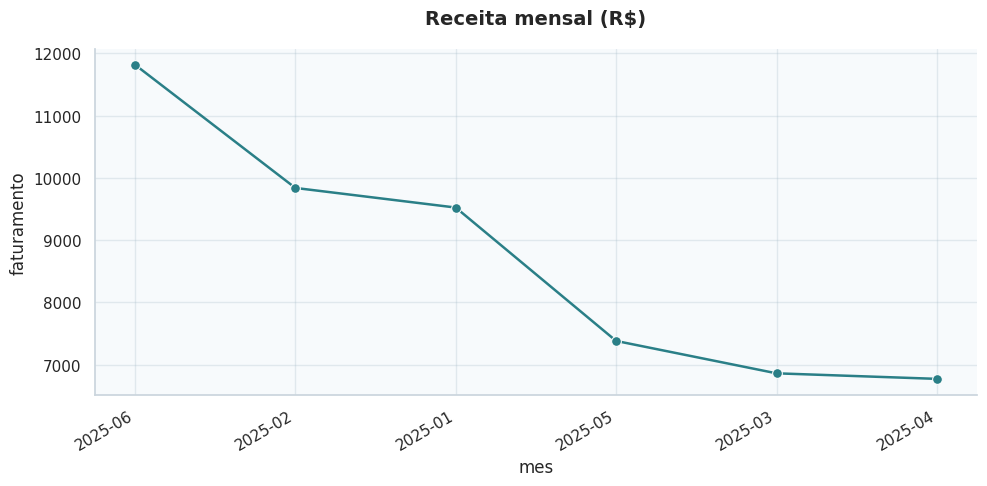

In [85]:
df_mensal = analise.agrupar("mes")
analise.grafico(linhas, df_mensal, "mes", "faturamento", "Receita mensal (R$)")